# Age at death and imputation of missing birth and death dates

In [1]:
import sys
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
sys.path.insert(0, '../../scripts/1-datamodels')
sys.path.insert(0, '../../scripts/3-raw_to_db/helpers')
from style import *
import datamodel_in_duckdb as D
from pydantic_to_duckdb_schema import duck_type

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
OUTPUT_PATH = Path('../../data/enriched_parquets/individual_dates_from_age_at_death.parquet')  # datamodel shape
SAVE = True  # True writes OUTPUT_PATH
KNOWN_PRECISIONS = ['day', 'month', 'year', 'decade']  # dates precise to the year or the decade
META_OCCUPATIONS = list(OCCUPATION_COLORS)  # the four occupational categories
ALL = 'All'  # no recorded meta occupation: the century alone
AGE_RANGE = (0, 110)  # plausible ages at death, in years
LAST_BIRTH_YEAR = 1920  # born later: may still be alive, no death imputed
MIN_COHORT = 10  # a smaller cohort takes the nearest century
CENTURY = 100  # years
TEST_SHARE = 0.2  # held-out share of the individuals with both dates
WITHIN = 10  # years between the imputed and the true date
FIRST_CENTURY = -800  # first century in the figure
CUTOFF = 1500  # split of the coverage table
SEED = 42

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
people = con.sql('''
    WITH held AS (
        SELECT entity.qid AS qid, unnest(occupation).entity.qid AS occupation_qid, generate_subscripts(occupation, 1) AS position
        FROM individual
    ),
    counted AS (
        SELECT held.qid, occupation.meta_occupation, count(*) AS occupations, min(held.position) AS first_position
        FROM held
        JOIN occupation ON occupation.entity.qid = held.occupation_qid
        WHERE list_contains($meta_occupations, occupation.meta_occupation)
        GROUP BY ALL
    ),
    main_meta_occupation AS (
        SELECT qid, meta_occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    ),
    wikidata AS (
        SELECT entity.qid AS qid,
               list_filter(birth_date, d -> d.field_provenance['year'].rule IS NULL) AS birth,
               list_filter(death_date, d -> d.field_provenance['year'].rule IS NULL) AS death
        FROM individual
    )
    SELECT wikidata.qid,
           coalesce(main_meta_occupation.meta_occupation, $all) AS meta_occupation,
           coalesce(wikidata.birth[1].year, wikidata.death[1].year) AS first_year,
           len(wikidata.birth) = 0 AS no_birth,
           len(wikidata.death) = 0 AS no_death,
           list_filter(wikidata.birth, d -> list_contains($known, d.precision))[1].year AS birth_year,
           list_filter(wikidata.death, d -> list_contains($known, d.precision))[1].year AS death_year
    FROM wikidata
    LEFT JOIN main_meta_occupation ON main_meta_occupation.qid = wikidata.qid
''', params={'known': KNOWN_PRECISIONS, 'meta_occupations': META_OCCUPATIONS, 'all': ALL}).pl()
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals')
people.sample(5, seed=SEED)

13,002,897 individuals


qid,meta_occupation,first_year,no_birth,no_death,birth_year,death_year
str,str,i64,bool,bool,i64,i64
"""Q88179272""","""Discovery/Science""",null,true,true,null,null
"""Q132777367""","""All""",null,true,true,null,null
"""Q95295120""","""Discovery/Science""",1913,false,true,1913,null
"""Q65894196""","""All""",null,true,true,null,null
"""Q8460250""","""All""",1976,false,true,1976,null


### Birth and death dates in Wikidata

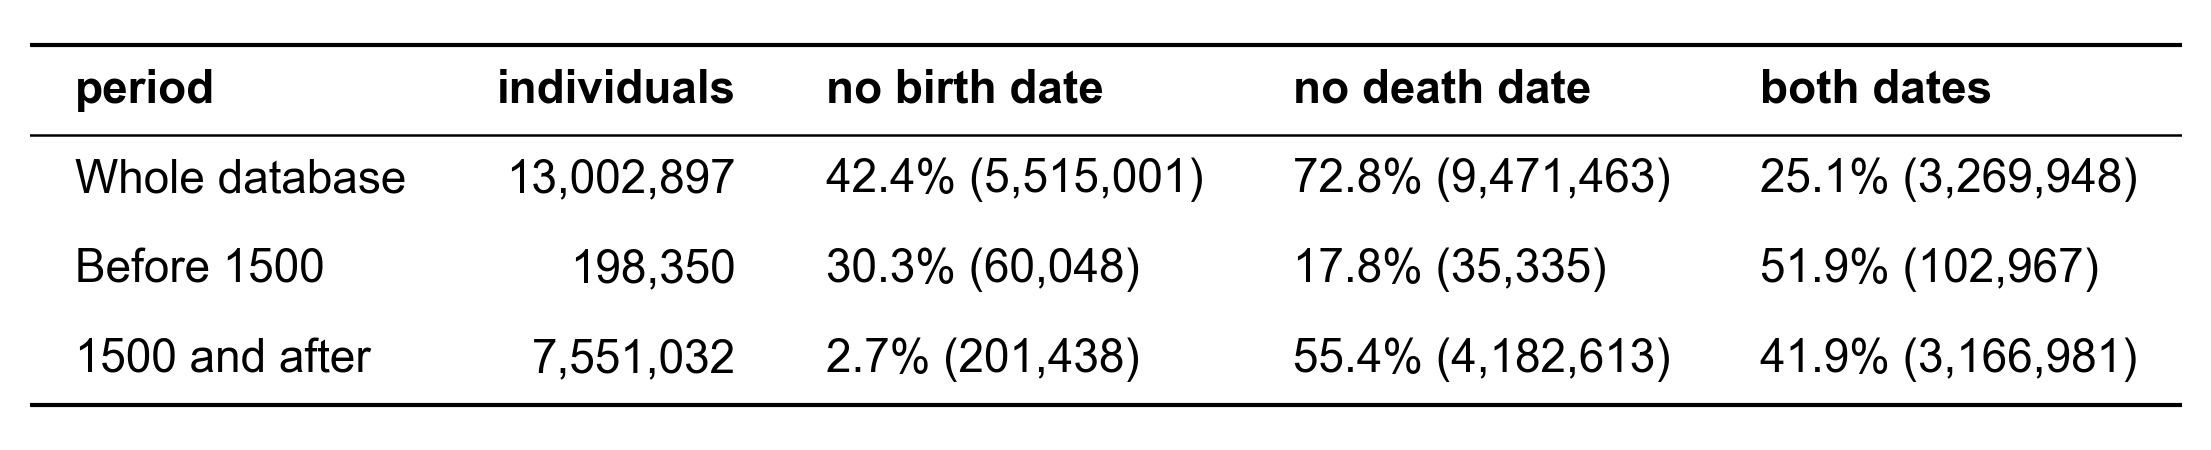

In [3]:
def share(mask):
    return f'{100 * mask.mean():.1f}% ({mask.sum():,})'


def coverage(period, frame):
    return {
        'period': period,
        'individuals': f'{frame.height:,}',
        'no birth date': share(frame['no_birth']),
        'no death date': share(frame['no_death']),
        'both dates': share(~frame['no_birth'] & ~frame['no_death']),
    }


show_table(pl.DataFrame([
    coverage('Whole database', people),
    coverage(f'Before {CUTOFF}', people.filter(pl.col('first_year') < CUTOFF)),
    coverage(f'{CUTOFF} and after', people.filter(pl.col('first_year') >= CUTOFF)),
]))

In [4]:
lives = (
    people.filter(pl.col('birth_year').is_not_null() & pl.col('death_year').is_not_null() & (pl.col('birth_year') <= LAST_BIRTH_YEAR))
    .with_columns((pl.col('death_year') - pl.col('birth_year')).alias('age_at_death'), (pl.col('birth_year') // CENTURY * CENTURY).alias('century'))
    .filter(pl.col('age_at_death').is_between(*AGE_RANGE))
)
missing_death = people.filter(pl.col('no_death') & (pl.col('birth_year') <= LAST_BIRTH_YEAR))
missing_birth = people.filter(pl.col('no_birth') & pl.col('death_year').is_not_null())
print(f'{lives.height:,} with both dates, {missing_death.height:,} missing a death, {missing_birth.height:,} missing a birth')

2,415,592 with both dates, 395,141 missing a death, 258,435 missing a birth


## Age at death

In [5]:
lives.group_by('meta_occupation').agg(
    pl.len().alias('individuals'),
    pl.col('age_at_death').mean().round(1).alias('mean_age_at_death'),
).sort('individuals', descending=True)

meta_occupation,individuals,mean_age_at_death
str,u32,f64
"""All""",810290,63.0
"""Leadership""",626975,68.2
"""Culture""",516922,70.1
"""Discovery/Science""",358420,71.7
"""Sports/Games""",102985,70.0


### Mean age at death per century of birth and occupation

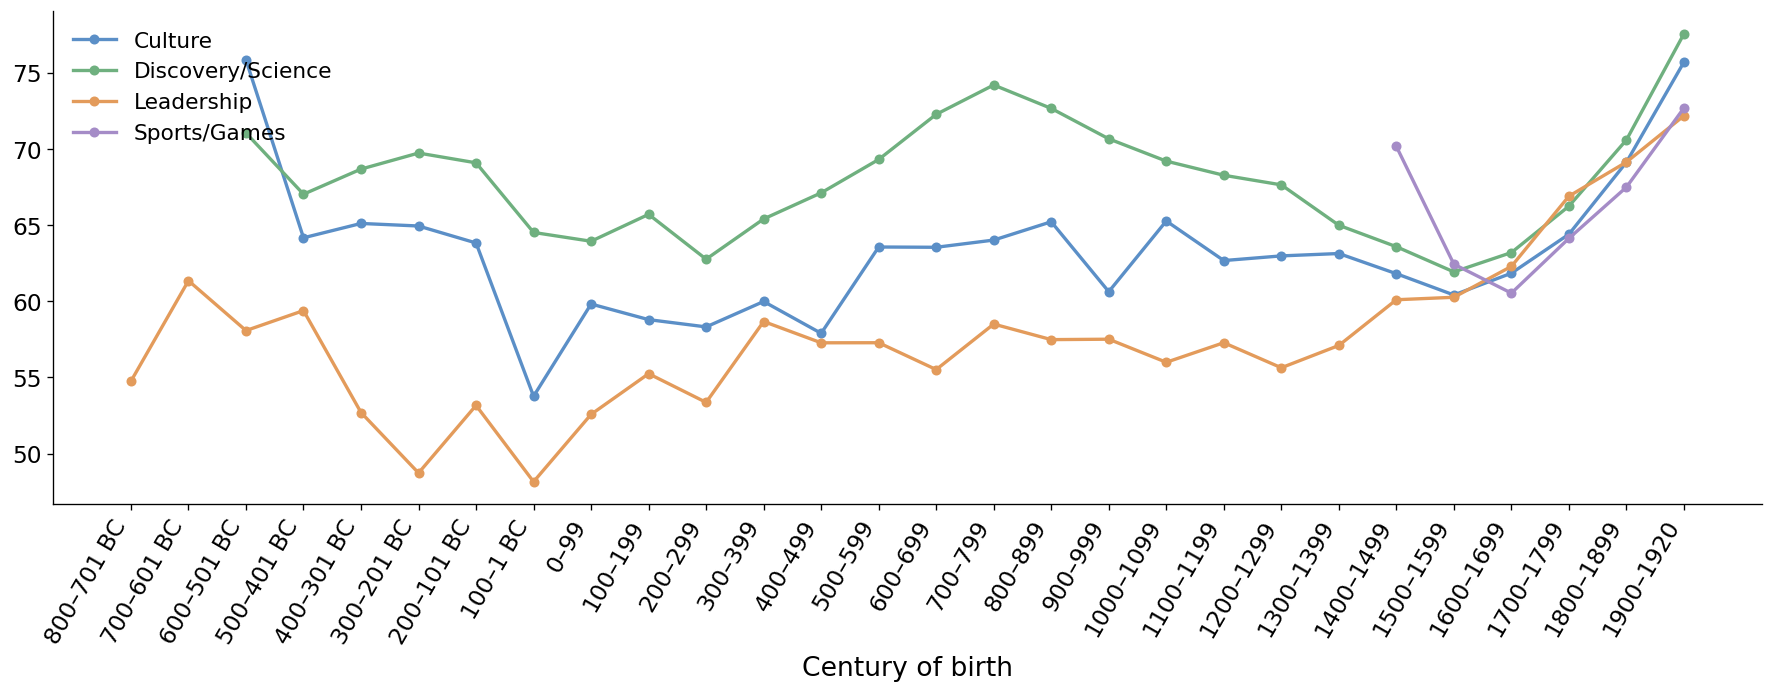

In [6]:
def century_label(start):
    end = min(start + CENTURY - 1, LAST_BIRTH_YEAR)
    return f'{start}–{end}' if start >= 0 else f'{-start}–{-end} BC'


per_century = (
    lives.filter(pl.col('century') >= FIRST_CENTURY)
    .group_by('meta_occupation', 'century')
    .agg(pl.len().alias('individuals'), pl.col('age_at_death').mean().alias('mean_age_at_death'))
    .filter(pl.col('individuals') >= MIN_COHORT)
    .sort('century')
)
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
for occupation, color in OCCUPATION_COLORS.items():
    rows = per_century.filter(pl.col('meta_occupation') == occupation)
    ax.plot(rows['century'], rows['mean_age_at_death'], color=color, linewidth=2, marker='o', markersize=5, label=occupation)
starts = list(range(FIRST_CENTURY, LAST_BIRTH_YEAR // CENTURY * CENTURY + 1, CENTURY))
ax.set_xticks(starts)
ax.set_xticklabels([century_label(start) for start in starts], rotation=60, ha='right', fontsize=14)
ax.set_xlabel('Century of birth')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## Model

In [7]:
first_century = min(people['birth_year'].min(), people['death_year'].min()) // CENTURY * CENTURY - CENTURY
centuries = pl.DataFrame({'century': range(first_century, LAST_BIRTH_YEAR // CENTURY * CENTURY + 1, CENTURY)})


def mean_age(lives, *keys):
    return lives.group_by(*keys).agg(pl.len().alias('cohort_individuals'), pl.col('age_at_death').mean().alias('age_at_death'))


def cohort_table(lives):
    """Mean age at death per meta occupation and century of birth, the century alone for ALL; a cohort under MIN_COHORT takes the nearest century."""
    cohorts = pl.concat([
        mean_age(lives.filter(pl.col('meta_occupation') != ALL), 'meta_occupation', 'century'),
        mean_age(lives, 'century').select(pl.lit(ALL).alias('meta_occupation'), pl.all()),
    ]).filter(pl.col('cohort_individuals') >= MIN_COHORT).rename({'century': 'cohort_century'})
    return (
        centuries.join(cohorts, how='cross')
        .sort((pl.col('cohort_century') - pl.col('century')).abs(), 'cohort_century', descending=[False, True])
        .group_by('meta_occupation', 'century', maintain_order=True).first()
    )


def impute(targets, cohorts, missing, global_age):
    """Death = birth + the mean age at death of the birth cohort; birth = death − it, the century of birth guessed as death − the global mean."""
    known, sign = ('birth', 1) if missing == 'death' else ('death', -1)
    guessed_birth = pl.col(f'{known}_year') - (0 if missing == 'death' else global_age)
    imputed = (
        targets.drop('age_at_death', strict=False).with_columns((guessed_birth // CENTURY * CENTURY).cast(pl.Int64).clip(first_century, centuries['century'].max()).alias('century'))
        .join(cohorts, on=['meta_occupation', 'century'], how='left')
        .with_columns((pl.col(f'{known}_year') + sign * pl.col('age_at_death').round()).cast(pl.Int64).alias(f'imputed_{missing}_year'))
    )
    assert imputed.height == targets.height and imputed[f'imputed_{missing}_year'].null_count() == 0
    return imputed

## Test on a held-out 20%

In [8]:
test = lives.sort('qid').sample(fraction=TEST_SHARE, shuffle=True, seed=SEED)
train = lives.join(test, on='qid', how='anti')
assert train.height + test.height == lives.height
train_age = train['age_at_death'].mean()
train_cohorts = cohort_table(train)
models = {
    'Overall mean': train_cohorts.with_columns(pl.lit(train_age).alias('age_at_death')),
    'Mean by century of birth': train_cohorts.drop('age_at_death').join(train_cohorts.filter(pl.col('meta_occupation') == ALL).select('century', 'age_at_death'), on='century'),
    'Mean by occupation': train_cohorts.drop('age_at_death').join(mean_age(train, 'meta_occupation').select('meta_occupation', 'age_at_death'), on='meta_occupation'),
    'Mean by century of birth × occupation': train_cohorts,
}
print(f'train: {train.height:,}, test: {test.height:,}, global mean age at death: {train_age:.1f}')

train: 1,932,474, test: 483,118, global mean age at death: 67.4


### Accuracy: % of the held-out 20% imputed within 10 years [mean absolute error, in years], each century of birth counting equally

26 centuries of birth, -800 to 1900


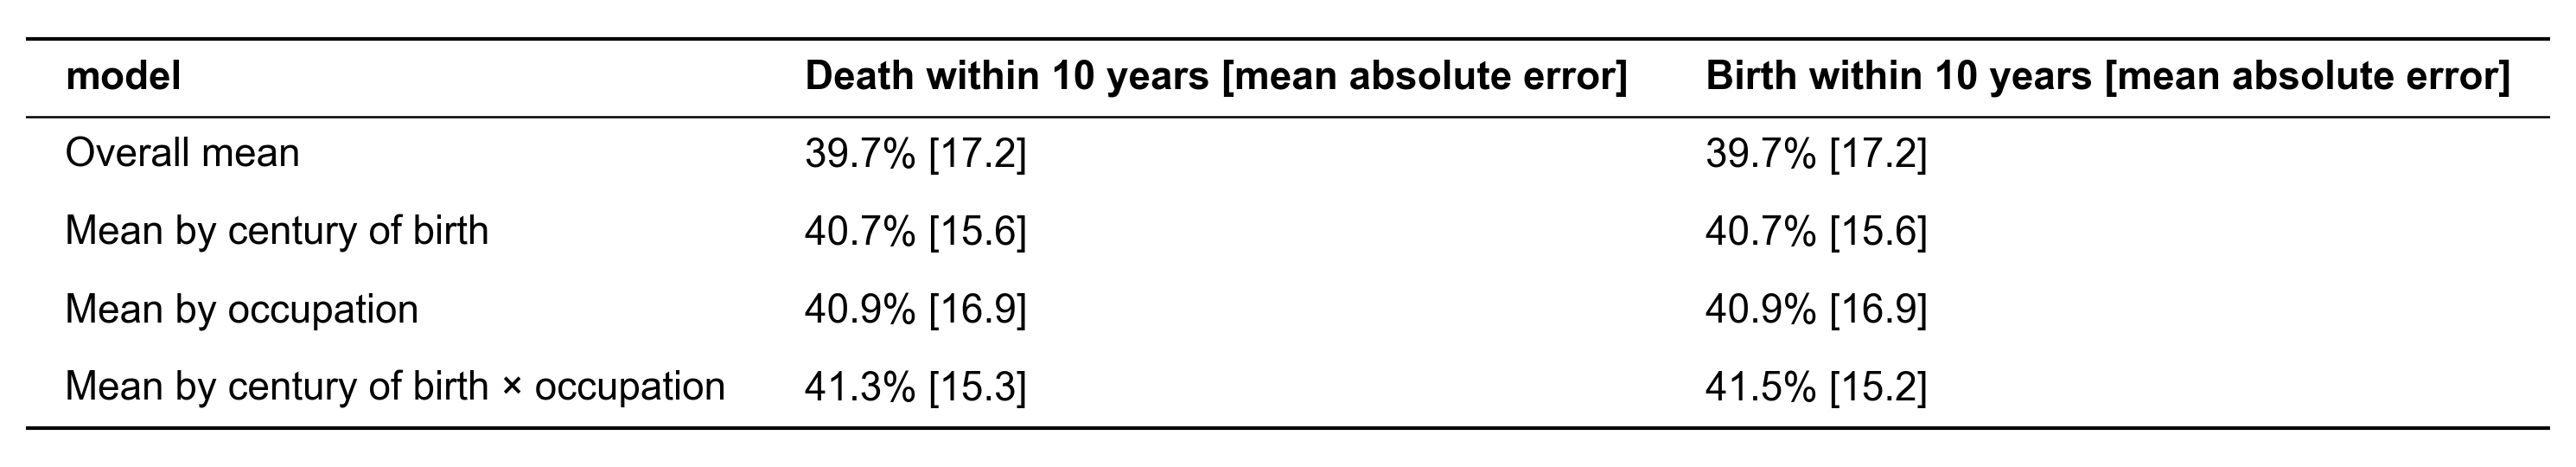

In [9]:
def century_scores(imputed, missing):
    return (
        imputed.select((pl.col('birth_year') // CENTURY * CENTURY).alias('birth_century'), (pl.col(f'imputed_{missing}_year') - pl.col(f'{missing}_year')).abs().alias('error'))
        .filter(pl.col('birth_century') >= FIRST_CENTURY)
        .group_by('birth_century')
        .agg(pl.len().alias('test_individuals'), (100 * (pl.col('error') <= WITHIN).mean()).alias('within'), pl.col('error').mean().alias('mean_absolute_error'))
        .filter(pl.col('test_individuals') >= MIN_COHORT)
    )


scores = {}
for model, cohorts in models.items():
    scores[model] = {'model': model}
    for missing in ['death', 'birth']:
        per_century = century_scores(impute(test, cohorts, missing, train_age), missing)
        scores[model][f'{missing.capitalize()} within {WITHIN} years [mean absolute error]'] = f"{per_century['within'].mean():.1f}% [{per_century['mean_absolute_error'].mean():.1f}]"
print(f'{per_century.height} centuries of birth, {FIRST_CENTURY} to {per_century["birth_century"].max()}')
show_table(pl.DataFrame(list(scores.values())))

## Imputation

In [10]:
global_age = lives['age_at_death'].mean()
cohorts = cohort_table(lives)
imputed = {'death': impute(missing_death, cohorts, 'death', global_age), 'birth': impute(missing_birth, cohorts, 'birth', global_age)}
pl.DataFrame([{
    'missing': missing,
    'imputed': frame.height,
    'from the nearest century': frame.filter(pl.col('cohort_century') != pl.col('century')).height,
    'from the century alone': frame.filter(pl.col('meta_occupation') == ALL).height,
    'mean age at death used': round(frame['age_at_death'].mean(), 1),
} for missing, frame in imputed.items()])

missing,imputed,from the nearest century,from the century alone,mean age at death used
str,i64,i64,i64,f64
"""death""",395141,60,256502,67.8
"""birth""",258435,96,174921,64.1


### Estimated births and deaths of the best-known individuals, with the cohort used

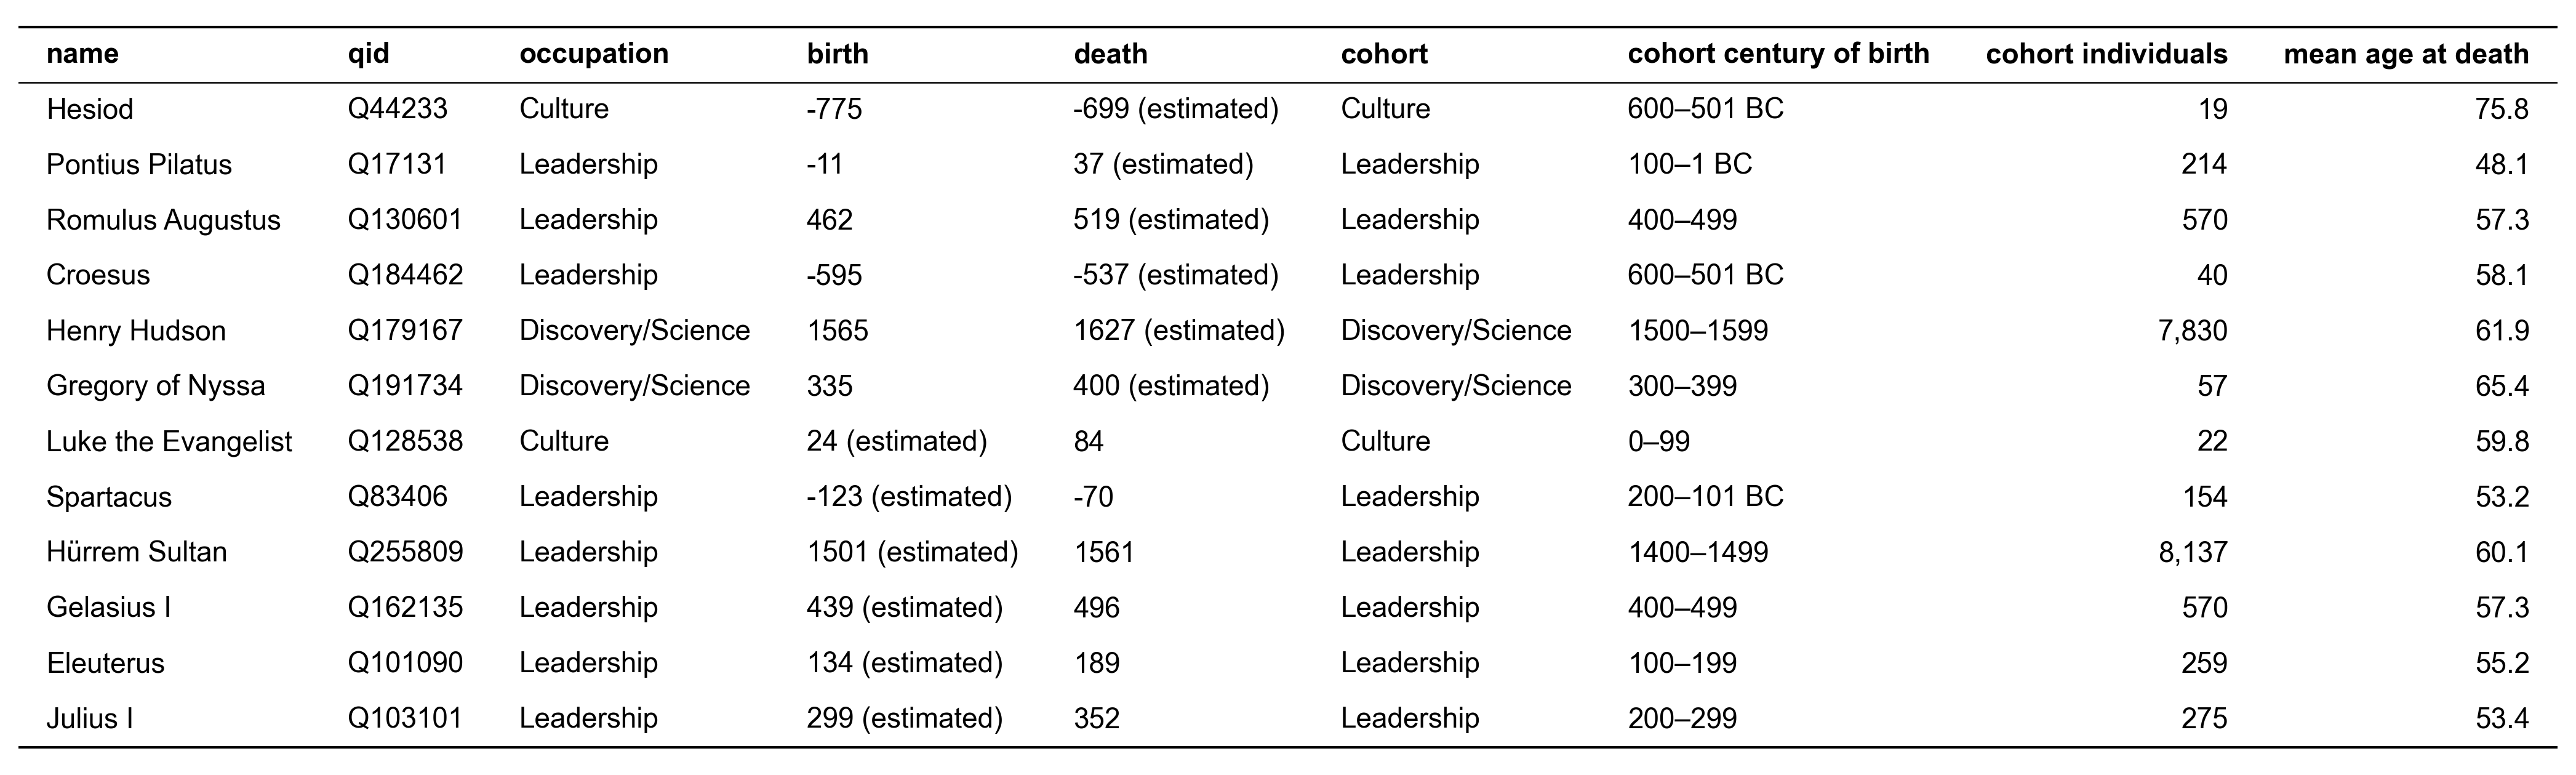

In [11]:
def best_known(frame, missing, n=6):
    con.register('candidates', frame.select('qid').to_arrow())
    known = con.sql('''
        SELECT entity.qid AS qid, coalesce(entity.label_en, entity.label_non_en) AS name, len(sitelink) AS sitelinks
        FROM individual
        JOIN candidates ON candidates.qid = individual.entity.qid
    ''').pl()
    return frame.join(known, on='qid').sort('sitelinks', 'qid', descending=[True, False]).head(n).with_columns(pl.lit(missing).alias('estimated'))


def year_text(column, missing):
    estimated = pl.col(f'imputed_{missing}_year').cast(pl.String) + ' (estimated)'
    return pl.col(column).cast(pl.String) if missing != column.split('_')[0] else estimated


examples = pl.concat([
    best_known(frame, missing).select(
        'name', 'qid',
        pl.col('meta_occupation').replace(ALL, '—').alias('occupation'),
        year_text('birth_year', missing).alias('birth'),
        year_text('death_year', missing).alias('death'),
        pl.when(pl.col('meta_occupation') == ALL).then(pl.lit('Everyone')).otherwise('meta_occupation').alias('cohort'),
        pl.col('cohort_century').map_elements(century_label, return_dtype=pl.String).alias('cohort century of birth'),
        pl.col('cohort_individuals').alias('cohort individuals'),
        pl.col('age_at_death').round(1).alias('mean age at death'),
    )
    for missing, frame in imputed.items()
])
show_table(examples, decimals=1)

## Save

In [12]:
DATE_TYPE = duck_type(D.IndividualDate)
INPUTS = ['Individual.birth_date', 'Individual.death_date', 'Occupation.meta_occupation']


def with_rule(frame, missing):
    operation = 'birth year +' if missing == 'death' else 'death year −'
    group = pl.when(pl.col('meta_occupation') == ALL).then(pl.lit('individuals')).otherwise(pl.col('meta_occupation') + ' individuals')
    nearest = (
        pl.when(pl.col('cohort_century') != pl.col('century'))
        .then(pl.format(f', the nearest century with at least {MIN_COHORT} individuals to {{}}–{{}}', 'century', pl.col('century') + CENTURY - 1))
        .otherwise(pl.lit(''))
    )
    rule = pl.format(f'Imputed from the age at death: {operation} {{}} years, the mean age at death of the {{}} {{}} born in {{}}–{{}}{{}}.',
                     pl.col('age_at_death').round(1), 'cohort_individuals', group, 'cohort_century', pl.col('cohort_century') + CENTURY - 1, nearest)
    cohort = pl.struct(
        pl.when(pl.col('meta_occupation') != ALL).then('meta_occupation').alias('occupation'),
        pl.col('cohort_century').alias('century'),
        pl.col('cohort_individuals').cast(pl.Int64).alias('individuals'),
        pl.col('age_at_death').alias('age'),
    )
    return frame.select('qid', pl.col(f'imputed_{missing}_year').alias('year'), rule.alias('rule'), cohort.alias('cohort'))


def imputed_date(missing):
    provenance = f"{{'raw': [], 'inputs': $inputs, 'rule': imputed_{missing}.rule, 'ai_answer': NULL, 'retrieved_on': NULL}}"
    return f"""CASE WHEN imputed_{missing}.qid IS NOT NULL THEN CAST({{'iso': NULL, 'year': imputed_{missing}.year, 'precision': 'year',
        'field_provenance': MAP {{'year': {provenance}, 'precision': {provenance}}}, 'source': 'estimated', 'cohort': imputed_{missing}.cohort}} AS {DATE_TYPE}) END"""


def wikidata_date(missing):
    stated = f"list_filter(individual.{missing}_date, d -> d.field_provenance['year'].rule IS NULL)[1]"
    return f"CASE WHEN {stated} IS NOT NULL THEN CAST(struct_insert({stated}, source := 'wikidata', cohort := NULL) AS {DATE_TYPE}) END"


for missing, frame in imputed.items():
    con.register(f'imputed_{missing}', with_rule(frame, missing).to_arrow())
DATES = f"""
    SELECT individual.entity.qid AS qid,
           coalesce({wikidata_date('birth')}, {imputed_date('birth')}) AS birth_date,
           coalesce({wikidata_date('death')}, {imputed_date('death')}) AS death_date
    FROM individual
    LEFT JOIN imputed_birth ON imputed_birth.qid = individual.entity.qid
    LEFT JOIN imputed_death ON imputed_death.qid = individual.entity.qid
"""
con.sql(f"SELECT * FROM ({DATES}) WHERE birth_date.source = 'estimated' OR death_date.source = 'estimated' LIMIT 4", params={'inputs': INPUTS}).pl()

qid,birth_date,death_date
str,struct[6],struct[6]
"""Q103791540""","{""1917-01-01"",1917,""year"",[{""iso"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}, {""year"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}, {""precision"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}],""wikidata"",null}","{null,1989,""year"",[{""year"",{[],[""Individual.birth_date"", ""Individual.death_date"", ""Occupation.meta_occupation""],""Imputed from the age at death: birth year + 71.8 years, the mean age at death of the 562239 individuals born in 1900–1999."",null,null}}, {""precision"",{[],[""Individual.birth_date"", ""Individual.death_date"", ""Occupation.meta_occupation""],""Imputed from the age at death: birth year + 71.8 years, the mean age at death of the 562239 individuals born in 1900–1999."",null,null}}],""estimated"",{null,1900,562239,71.819447}}"
"""Q104708350""","{""1916-01-01"",1916,""year"",[{""iso"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}, {""year"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}, {""precision"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}],""wikidata"",null}","{null,1988,""year"",[{""year"",{[],[""Individual.birth_date"", ""Individual.death_date"", ""Occupation.meta_occupation""],""Imputed from the age at death: birth year + 71.8 years, the mean age at death of the 562239 individuals born in 1900–1999."",null,null}}, {""precision"",{[],[""Individual.birth_date"", ""Individual.death_date"", ""Occupation.meta_occupation""],""Imputed from the age at death: birth year + 71.8 years, the mean age at death of the 562239 individuals born in 1900–1999."",null,null}}],""estimated"",{null,1900,562239,71.819447}}"
"""Q104713185""","{""1917-12-01"",1917,""day"",[{""iso"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}, {""year"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}, {""precision"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}],""wikidata"",null}","{null,1989,""year"",[{""year"",{[],[""Individual.birth_date"", ""Individual.death_date"", ""Occupation.meta_occupation""],""Imputed from the age at death: birth year + 72.2 years, the mean age at death of the 116501 Leadership individuals born in 1900–1999."",null,null}}, {""precision"",{[],[""Individual.birth_date"", ""Individual.death_date"", ""Occupation.meta_occupation""],""Imputed from the age at death: birth year + 72.2 years, the mean age at death of the 116501 Leadership individuals born in 1900–1999."",null,null}}],""estimated"",{""Leadership"",1900,116501,72.17811}}"
"""Q100139704""","{""1919-01-01"",1919,""year"",[{""iso"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}, {""year"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}, {""precision"",{[""IndividualWikidata.date_of_birth"", ""IndividualWikidata.date_of_birth_precision""],[],null,null,null}}],""wikidata"",null}","{null,1997,""year"",[{""year"",{[],[""Individual.birth_date"", ""Individual.death_date"", ""Occupation.meta_occupation""],""Imputed from the age at death: birth year + 77.6 years, the mean age at death of the 100614 Discovery/Science individuals born in 1900–1999."",null,null}}, {""precision"",{[],[""Individual.birth_date"", ""Individual.death_date"", ""Occupation.meta_occupation""],""Imputed from the age at death: birth year + 77.6 years, the mean age at death of the 100614 Discovery/Science individuals born in 1900–1999."",null,n

In [13]:
if SAVE:
    OUTPUT_PATH.parent.mkdir(exist_ok=True)
    con.execute(f"COPY ({DATES} ORDER BY qid) TO '{OUTPUT_PATH}' (FORMAT parquet)", {'inputs': INPUTS})
    saved = con.sql(f"SELECT count(*) AS individuals, count(*) FILTER (birth_date.source = 'estimated') AS imputed_births, count(*) FILTER (death_date.source = 'estimated') AS imputed_deaths FROM '{OUTPUT_PATH}'").pl()
    assert saved['imputed_births'][0] == imputed['birth'].height and saved['imputed_deaths'][0] == imputed['death'].height
    display(saved)

individuals,imputed_births,imputed_deaths
i64,i64,i64
13002897,258435,395141
